# 🎓 Material de Clase Magistral: Algoritmos de Ordenamiento
## Unidades 27, 28 y 29: De los Métodos Elementales a Divide y Vencerás

---

### 📋 Temario Cubierto en este Cuaderno Interactivo
* **Unidad 27:** Ordenamiento por Burbujas (*Bubble Sort*), Selección (*Selection Sort*) e Inserción (*Insertion Sort*).
* **Unidad 28:** Ordenamiento por Fusión (*Merge Sort*).
* **Unidad 29:** Ordenamiento Rápido (*Quick Sort*).

---

### 🌐 1. Introducción General: ¿Qué es el Ordenamiento y por qué es un Pilar de la Computación Moderna?

El **ordenamiento** (*sorting*) es el proceso de reorganizar una colección de elementos (números, cadenas de texto, registros financieros, objetos complejos, paquetes de red) siguiendo una relación de orden bien definida (ascendente, descendente, lexicográfica o personalizada mediante llaves).

Aunque a primera vista parece una operación elemental, el ordenamiento es uno de los problemas más estudiados en la historia de las Ciencias de la Computación. Se estima que entre el **25% y el 50% del tiempo de cómputo en servidores empresariales y bases de datos** involucra directa o indirectamente operaciones de ordenamiento o estructuras que mantienen datos ordenados.

#### 🚀 ¿Por qué son tan importantes en la Programación Moderna?
1. **Habilitador de la Búsqueda Binaria ($O(\log n)$):** Buscar un dato en una lista desordenada de $10,000,000$ de registros requiere hasta $10,000,000$ de comparaciones ($O(n)$). Si la lista está ordenada, la **búsqueda binaria** encuentra cualquier registro en a lo sumo **$24$ comparaciones** ($\log_2(10^7) \approx 23.25$).
2. **Motores de Bases de Datos Relacionales y NoSQL:** Las cláusulas `ORDER BY`, `GROUP BY`, `DISTINCT` y los cruces de tablas mediante **Sort-Merge Join** en PostgreSQL, MySQL, Oracle y Spark SQL dependen directamente de variantes optimizadas de *Merge Sort* y *Quick Sort*.
3. **Algoritmos Híbridos en Lenguajes Modernos (*Timsort* y *pdqsort*):**
   * **Python (`list.sort()` / `sorted()`) y Java (`Arrays.sort()` para objetos):** Utilizan **Timsort**, un algoritmo híbrido creado por Tim Peters que combina **Ordenamiento por Inserción** (Unidad 27) para tramos pequeños y **Ordenamiento por Fusión** (Unidad 28) para combinar bloques ordenados (*runs*).
   * **C++ (`std::sort`), Rust y Go:** Utilizan **Introsort** o **Pattern-Defeating Quicksort (`pdqsort`)**, que arrancan con **Ordenamiento Rápido** (Unidad 29), cambian a *HeapSort* si la recursión se profundiza demasiado, y finalizan con **Ordenamiento por Inserción** (Unidad 27) en particiones menores a 16–32 elementos.
4. **Gráficos por Computadora, Videojuegos y Ciencia de Datos:** El renderizado de objetos transparentes (*Painter's Algorithm / Z-sorting*), la construcción de árboles espaciales (*BVH / KD-Trees* para *Ray Tracing*), el cálculo de percentiles/medianas en `pandas`/`numpy` y los rankings de recomendaciones en tiempo real se apoyan en estos algoritmos.

---

### 🧭 Conceptos Clave para Evaluar un Algoritmo de Ordenamiento

Antes de analizar cada unidad, todo desarrollador e ingeniero de software debe dominar cuatro criterios técnicos:

| Criterio Técnico | Definición Clara | Impacto en la Práctica |
| :--- | :--- | :--- |
| **Complejidad Temporal ($O$)** | Cantidad de comparaciones e intercambios en función del tamaño de entrada $n$ (Mejor caso $\Omega$, Caso promedio $\Theta$, Peor caso $O$). | Determina si el algoritmo tardará milisegundos o días al pasar de $1,000$ a $1,000,000$ de datos. |
| **Complejidad Espacial** | Memoria RAM adicional requerida más allá del arreglo original. | Crucial en sistemas embebidos, IoT o *Big Data* donde duplicar un arreglo en RAM puede causar un `MemoryError`. |
| **Estabilidad (*Stability*)** | Un algoritmo es **estable** si preserva el orden relativo original de elementos que tienen claves iguales. | Indispensable cuando ordenamos una tabla por múltiples columnas (ej. ordenar primero por *Nombre* y luego por *Departamento* sin perder el orden alfabético dentro de cada departamento). |
| **Adaptabilidad (*Adaptiveness*)** | Capacidad del algoritmo de ejecutarse más rápido cuando los datos de entrada ya están parcial o totalmente ordenados. | En flujos de datos reales (logs por fecha, carritos de compra), los datos rara vez son 100% aleatorios; un algoritmo adaptativo aprovecha ese orden previo. |

```
                   ┌──────────────────────────────────────────────┐
                   │        ALGORITMOS DE ORDENAMIENTO            │
                   └──────────────────────┬───────────────────────┘
                                          │
                 ┌────────────────────────┴────────────────────────┐
                 ▼                                                 ▼
   ┌───────────────────────────────────┐             ┌───────────────────────────────────┐
   │  UNIDAD 27: MÉTODOS ELEMENTALES   │             │ UNIDADES 28 Y 29: DIVIDE Y VENCERÁS│
   │     Complejidad Promedio O(n²)    │             │   Complejidad Promedio O(n log n) │
   ├───────────────────────────────────┤             ├───────────────────────────────────┤
   │ • Burbuja (Bubble Sort)           │             │ • Unidad 28: Fusión (Merge Sort)  │
   │ • Selección (Selection Sort)      │             │   -> Estable, O(n) memoria extra  │
   │ • Inserción (Insertion Sort)      │             │ • Unidad 29: Rápido (Quick Sort)  │
   │   -> Base de Timsort e Introsort  │             │   -> In-place, ultra rápido caché │
   └───────────────────────────────────┘             └───────────────────────────────────┘
```

In [ ]:
# Configuración inicial del entorno gráfico y librerías para nuestras demostraciones y gráficas
import time
import random
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Estilo visual limpio y pedagógico para todas las gráficas del cuaderno
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

print("✅ Entorno de clase configurado correctamente. Listo para explorar las Unidades 27, 28 y 29.")

✅ Entorno de clase configurado correctamente. Listo para explorar las Unidades 27, 28 y 29.


---
# 📘 UNIDAD 27: Ordenamiento por Burbujas, Selección e Inserción
### (*Algoritmos Elementales o Cuadráticos — Familia $O(n^2)$*)

Los algoritmos de la **Unidad 27** constituyen la base pedagógica y algorítmica del ordenamiento. Se denominan **cuadráticos** porque, en el caso promedio y peor caso, su número de operaciones crece proporcionalmente al cuadrado del tamaño de la entrada ($n^2$). Sin embargo, **son in-place** ($O(1)$ de memoria adicional) y tienen un overhead de código mínimo.

---

## 27.1 Ordenamiento por Burbujas (*Bubble Sort*)

### 🔍 Explicación Conceptual Profunda
El **Ordenamiento por Burbujas** funciona recorriendo repetidamente la lista, comparando **pares de elementos adyacentes** (`arr[j]` y `arr[j + 1]`) e intercambiándolos (*swap*) si están en el orden incorrecto.

Su nombre proviene de una analogía física: en cada pasada completa de izquierda a derecha, el elemento más grande aún no ordenado "flota" o "burbujea" hacia su posición definitiva al final del arreglo, como una burbuja de aire que sube hacia la superficie del agua.

#### 💡 La Optimización de Parada Temprana (`intercambiado = False`)
Una implementación ingenua de *Bubble Sort* siempre ejecuta $n-1$ pasadas aunque el arreglo ya esté ordenado en la primera pasada. Al agregar una bandera booleana (`intercambiado`), si durante una pasada completa **no se realiza ningún intercambio**, sabemos con certeza matemática que todos los pares adyacentes cumplen `arr[j] <= arr[j+1]`, por lo que el arreglo está 100% ordenado y el algoritmo termina inmediatamente en tiempo lineal **$O(n)$**.

#### 📐 Diagrama de Flujo y Traza Paso a Paso (Arreglo: `[5, 1, 4, 2, 8]`)
```
PASADA 1 (El mayor elemento '8' burbujea hasta el final):
  [ 5, 1, 4, 2, 8 ]  --> Compara (5, 1): 5 > 1  ==> Intercambia ==> [ 1, 5, 4, 2, 8 ]
  [ 1, 5, 4, 2, 8 ]  --> Compara (5, 4): 5 > 4  ==> Intercambia ==> [ 1, 4, 5, 2, 8 ]
  [ 1, 4, 5, 2, 8 ]  --> Compara (5, 2): 5 > 2  ==> Intercambia ==> [ 1, 4, 2, 5, 8 ]
  [ 1, 4, 2, 5, 8 ]  --> Compara (5, 8): 5 <= 8 ==> No cambia   ==> [ 1, 4, 2, 5 | 8 ] (8 fijo)

PASADA 2 (El siguiente mayor '5' ya está en su lugar, '4' se acomoda):
  [ 1, 4, 2, 5 | 8 ] --> Compara (1, 4): 1 <= 4 ==> No cambia   ==> [ 1, 4, 2, 5 | 8 ]
  [ 1, 4, 2, 5 | 8 ] --> Compara (4, 2): 4 > 2  ==> Intercambia ==> [ 1, 2, 4, 5 | 8 ]
  [ 1, 2, 4, 5 | 8 ] --> Compara (4, 5): 4 <= 5 ==> No cambia   ==> [ 1, 2, 4 | 5, 8 ] (5 fijo)

PASADA 3 (Detección de arreglo ya ordenado):
  [ 1, 2, 4 | 5, 8 ] --> Compara (1, 2): 1 <= 2 (Sin cambio)
  [ 1, 2, 4 | 5, 8 ] --> Compara (2, 4): 2 <= 4 (Sin cambio)
  --> ¡0 intercambios en la Pasada 3! Bandera `intercambiado == False` -> FIN TEMPRANO.
```

#### 🛠️ Usos Prácticos en la Programación Moderna
* **Detección ultrarrápida de secuencias ya ordenadas:** Con la bandera de corte temprano, verificar que un flujo de datos ya viene ordenado toma exactamente $n-1$ comparaciones y $0$ escrituras en memoria.
* **Corrección de "casi ordenados" con errores locales (*k-sorted* con inversiones adyacentes):** En gráficos por computadora o telemetría donde un elemento solo se desfasó una posición respecto al frame anterior.
* **Enseñanza de invariantes de ciclo y optimización de límites.**

In [ ]:
def bubble_sort_explicado(arr, verbose=True):
    '''
    Implementación de Ordenamiento por Burbujas (Bubble Sort) con:
    - Bandera de corte temprano (optimización adaptativa O(n)).
    - Conteo exacto de comparaciones e intercambios.
    - Historial de estados para visualización gráfica.
    '''
    datos = arr.copy()
    n = len(datos)
    comparaciones = 0
    intercambios = 0
    historial = [("Estado Inicial", datos.copy(), -1, n)]

    for i in range(n - 1):
        intercambiado = False
        # En la pasada i, los últimos i elementos ya están en su posición final
        for j in range(0, n - 1 - i):
            comparaciones += 1
            if datos[j] > datos[j + 1]:
                # Intercambio (swap) de elementos adyacentes
                datos[j], datos[j + 1] = datos[j + 1], datos[j]
                intercambios += 1
                intercambiado = True

        historial.append((f"Fin Pasada {i + 1}", datos.copy(), -1, n - 1 - i))
        if verbose:
            print(f"  Pasada {i + 1}: {datos} | Intercambios acumulados: {intercambios}")

        # Si no hubo ningún intercambio en toda la pasada, la lista ya está ordenada
        if not intercambiado:
            if verbose:
                print(f"  ⚡ [Parada Temprana] Sin intercambios en la pasada {i + 1}. ¡Arreglo ordenado!")
            break

    return datos, comparaciones, intercambios, historial


# --- EJEMPLO PRÁCTICO 1: Traza algorítmica y Caso Real ---
print("=" * 72)
print("EJEMPLO 1A: Traza paso a paso de Bubble Sort")
print("=" * 72)
muestra_burbuja = [64, 34, 25, 12, 22, 11, 90]
print(f"Arreglo original: {muestra_burbuja}\n")
ordenado_b, comp_b, swap_b, hist_b = bubble_sort_explicado(muestra_burbuja)
print(f"\nResultado final : {ordenado_b}")
print(f"Total comparaciones: {comp_b} | Total intercambios: {swap_b}")

print("\n" + "=" * 72)
print("EJEMPLO 1B: Caso Práctico — Verificación de Telemetría Casi Ordenada")
print("=" * 72)
# En sensores IoT, las marcas de tiempo suelen llegar ordenadas salvo un paquete retrasado
marcas_tiempo_iot = [1001, 1002, 1004, 1003, 1005, 1006, 1007, 1008]
print(f"Paquetes recibidos: {marcas_tiempo_iot}")
_, comp_iot, swap_iot, _ = bubble_sort_explicado(marcas_tiempo_iot)
print(f"Observa cómo en solo 2 pasadas ({comp_iot} comparaciones y {swap_iot} intercambio) se corrige y valida el flujo.")

EJEMPLO 1A: Traza paso a paso de Bubble Sort
Arreglo original: [64, 34, 25, 12, 22, 11, 90]

  Pasada 1: [34, 25, 12, 22, 11, 64, 90] | Intercambios acumulados: 5
  Pasada 2: [25, 12, 22, 11, 34, 64, 90] | Intercambios acumulados: 9
  Pasada 3: [12, 22, 11, 25, 34, 64, 90] | Intercambios acumulados: 12
  Pasada 4: [12, 11, 22, 25, 34, 64, 90] | Intercambios acumulados: 13
  Pasada 5: [11, 12, 22, 25, 34, 64, 90] | Intercambios acumulados: 14
  Pasada 6: [11, 12, 22, 25, 34, 64, 90] | Intercambios acumulados: 14
  ⚡ [Parada Temprana] Sin intercambios en la pasada 6. ¡Arreglo ordenado!

Resultado final : [11, 12, 22, 25, 34, 64, 90]
Total comparaciones: 21 | Total intercambios: 14

EJEMPLO 1B: Caso Práctico — Verificación de Telemetría Casi Ordenada
Paquetes recibidos: [1001, 1002, 1004, 1003, 1005, 1006, 1007, 1008]
  Pasada 1: [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008] | Intercambios acumulados: 1
  Pasada 2: [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008] | Intercambios acumula

---
## 27.2 Ordenamiento por Selección (*Selection Sort*)

### 🔍 Explicación Conceptual Profunda
El **Ordenamiento por Selección** divide conceptualmente el arreglo en dos subregiones:
1. **Sublista izquierda (ya ordenada):** Crece de izquierda a derecha desde tamaño $0$ hasta $n$.
2. **Sublista derecha (por ordenar):** Se reduce en cada iteración.

En cada iteración $i$, el algoritmo recorre toda la sublista derecha buscando el **índice del elemento mínimo** (`min_idx`). Una vez que termina de explorar toda la región desordenada, realiza **un único intercambio** entre el elemento mínimo encontrado (`arr[min_idx]`) y el primer elemento de la zona desordenada (`arr[i]`).

#### 🔑 Propiedad Fundamental: Minimización de Escrituras en Memoria ($O(n)$ Swaps)
A diferencia de *Bubble Sort* (que puede realizar hasta $\frac{n(n-1)}{2}$ intercambios), *Selection Sort* realiza **como máximo $n-1$ intercambios** en el peor de los casos. Sin embargo, **no es adaptativo**: siempre realiza exactamente $\frac{n(n-1)}{2}$ comparaciones sin importar si el arreglo ya estaba ordenado, porque necesita recorrer todo el resto de la lista para asegurarse de cuál es el mínimo.

#### 📐 Diagrama de Traza Paso a Paso (Arreglo: `[29, 10, 14, 37, 13]`)
```
Estado Inicial: [ 29, 10, 14, 37, 13 ]   (Zona ordenada: vacía)

Iteración i=0: Busca el mínimo desde índice 0 hasta 4 -> Mínimo es 10 (índice 1)
               Intercambia pos[0] (29) <--> pos[1] (10)
               Resultado: [ 10 | 29, 14, 37, 13 ]

Iteración i=1: Busca el mínimo desde índice 1 hasta 4 -> Mínimo es 13 (índice 4)
               Intercambia pos[1] (29) <--> pos[4] (13)
               Resultado: [ 10, 13 | 14, 37, 29 ]

Iteración i=2: Busca el mínimo desde índice 2 hasta 4 -> Mínimo es 14 (índice 2)
               Ya está en pos[2] (0 movimientos innecesarios)
               Resultado: [ 10, 13, 14 | 37, 29 ]

Iteración i=3: Busca el mínimo desde índice 3 hasta 4 -> Mínimo es 29 (índice 4)
               Intercambia pos[3] (37) <--> pos[4] (29)
               Resultado: [ 10, 13, 14, 29, 37 ]  --> ¡ORDENADO!
```

#### 🛠️ Usos Prácticos en la Programación Moderna
* **Memorias Flash, EEPROM y Sistemas Embebidos:** En microcontroladores donde las lecturas de memoria son muy rápidas y gratuitas, pero **las escrituras en memoria desgastan físicamente las celdas** (ciclos de escritura limitados en EEPROM/Flash) o son sumamente costosas, *Selection Sort* es ideal porque garantiza a lo sumo $n-1$ escrituras de intercambio.
* **Movimientos de bloques físicos grandes:** Cuando las llaves de comparación son pequeñas (un ID entero) pero intercambiar dos elementos implica mover estructuras pesadas en disco o buffers físicos.

In [ ]:
def selection_sort_explicado(arr, verbose=True):
    '''
    Implementación de Ordenamiento por Selección (Selection Sort).
    Destaca por realizar a lo sumo (n - 1) intercambios en memoria.
    '''
    datos = arr.copy()
    n = len(datos)
    comparaciones = 0
    intercambios = 0
    historial = [("Estado Inicial", datos.copy(), -1, 0)]

    for i in range(n - 1):
        min_idx = i
        # Buscar el elemento mínimo en el subarreglo desordenado datos[i+1 .. n-1]
        for j in range(i + 1, n):
            comparaciones += 1
            if datos[j] < datos[min_idx]:
                min_idx = j

        # Realizar el intercambio solo si el mínimo no está ya en la posición i
        if min_idx != i:
            datos[i], datos[min_idx] = datos[min_idx], datos[i]
            intercambios += 1

        historial.append((f"Iteración {i + 1} (Mín={datos[i]})", datos.copy(), i, i + 1))
        if verbose:
            print(f"  Iteración {i + 1}: Mínimo seleccionado = {datos[i]:2d} -> {datos} (Swaps acumulados: {intercambios})")

    return datos, comparaciones, intercambios, historial


print("=" * 72)
print("EJEMPLO 2: Selection Sort en Memoria con Ciclos de Escritura Limitados (EEPROM)")
print("=" * 72)
calibracion_sensores = [64, 25, 12, 22, 11, 90, 34]
print(f"Tabla de calibración desordenada: {calibracion_sensores}\n")
ordenado_s, comp_s, swap_s, hist_s = selection_sort_explicado(calibracion_sensores)
print(f"\nTabla ordenada: {ordenado_s}")
print(f"Total comparaciones: {comp_s} | Total escrituras (swaps): {swap_s} (¡Mínimo desgaste de memoria!)")

EJEMPLO 2: Selection Sort en Memoria con Ciclos de Escritura Limitados (EEPROM)
Tabla de calibración desordenada: [64, 25, 12, 22, 11, 90, 34]

  Iteración 1: Mínimo seleccionado = 11 -> [11, 25, 12, 22, 64, 90, 34] (Swaps acumulados: 1)
  Iteración 2: Mínimo seleccionado = 12 -> [11, 12, 25, 22, 64, 90, 34] (Swaps acumulados: 2)
  Iteración 3: Mínimo seleccionado = 22 -> [11, 12, 22, 25, 64, 90, 34] (Swaps acumulados: 3)
  Iteración 4: Mínimo seleccionado = 25 -> [11, 12, 22, 25, 64, 90, 34] (Swaps acumulados: 3)
  Iteración 5: Mínimo seleccionado = 34 -> [11, 12, 22, 25, 34, 90, 64] (Swaps acumulados: 4)
  Iteración 6: Mínimo seleccionado = 64 -> [11, 12, 22, 25, 34, 64, 90] (Swaps acumulados: 5)

Tabla ordenada: [11, 12, 22, 25, 34, 64, 90]
Total comparaciones: 21 | Total escrituras (swaps): 5 (¡Mínimo desgaste de memoria!)


---
## 27.3 Ordenamiento por Inserción (*Insertion Sort*)

### 🔍 Explicación Conceptual Profunda
El **Ordenamiento por Inserción** trabaja exactamente igual a como una persona ordena una mano de cartas de póker o UNO:
1. Comenzamos asumiendo que la primera carta (`arr[0]`) ya está ordenada por sí sola.
2. Tomamos la siguiente carta (`llave = arr[i]`) en nuestra mano derecha.
3. Comparamos esa `llave` de derecha a izquierda contra las cartas ya ordenadas de nuestra mano izquierda (`arr[i-1], arr[i-2], ...`).
4. Desplazamos una posición hacia la derecha todas las cartas mayores que nuestra `llave` para abrir espacio, e **insertamos** la `llave` en el hueco exacto que le corresponde.

#### 📐 Diagrama de Traza Paso a Paso (Arreglo: `[12, 11, 13, 5, 6]`)
```
Inicio:  [ 12 | 11, 13, 5, 6 ]   --> Sublista ordenada inicial: [12]

i = 1 (llave = 11):
  12 > 11 -> Desplaza 12 a la derecha -> [ _, 12 | 13, 5, 6 ]
  Inserta 11 en pos[0]                -> [ 11, 12 | 13, 5, 6 ]

i = 2 (llave = 13):
  12 <= 13 -> No desplaza nada        -> [ 11, 12, 13 | 5, 6 ]

i = 3 (llave = 5):
  13 > 5  -> Desplaza 13              -> [ 11, 12, _, 13 | 6 ]
  12 > 5  -> Desplaza 12              -> [ 11, _, 12, 13 | 6 ]
  11 > 5  -> Desplaza 11              -> [ _, 11, 12, 13 | 6 ]
  Inserta 5 en pos[0]                 -> [ 5, 11, 12, 13 | 6 ]

i = 4 (llave = 6):
  13 > 6, 12 > 6, 11 > 6 -> Desplaza 13, 12 y 11; se detiene ante 5 (5 <= 6)
  Inserta 6 en pos[1]                 -> [ 5, 6, 11, 12, 13 ]  --> ¡ORDENADO!
```

#### 🌟 ¿Por qué *Insertion Sort* es el Algoritmo Elemental MÁS Importante Hoy en Día?
Aunque su peor caso es $O(n^2)$, **Insertion Sort es el campeón indiscutible en arreglos pequeños ($n \le 32$) y en arreglos casi ordenados**:
1. **Componente interno de `Timsort` (Python/Java/Android/V8) e `Introsort` (C++/Rust/.NET):** Cuando *QuickSort* o *MergeSort* dividen un arreglo grande hasta llegar a subarreglos de 16 a 32 elementos, dejan de hacer llamadas recursivas y **llaman a Insertion Sort**, porque para tamaños pequeños tiene menor sobrecarga de instrucciones y aprovecha al máximo la línea de caché L1 del procesador.
2. **Algoritmo *Online* (Tiempo Real):** Puede ir ordenando datos a medida que van llegando por red o teclado sin necesidad de tener todo el conjunto de datos completo en memoria desde el inicio.
3. **Estable y Adaptativo ($O(n + d)$):** Su tiempo de ejecución es proporcional a $n + d$, donde $d$ es el número de *inversiones* (pares desordenados). Si la lista está casi ordenada, corre en tiempo prácticamente lineal $O(n)$.

In [ ]:
def insertion_sort_explicado(arr, verbose=True):
    '''
    Implementación de Ordenamiento por Inserción (Insertion Sort).
    Utiliza desplazamientos (shifts) en lugar de swaps completos para mayor eficiencia.
    '''
    datos = arr.copy()
    n = len(datos)
    comparaciones = 0
    desplazamientos = 0
    historial = [("Estado Inicial", datos.copy(), 0, 1)]

    for i in range(1, n):
        llave = datos[i]
        j = i - 1

        # Desplazar los elementos de datos[0..i-1] que son mayores que la llave
        while j >= 0:
            comparaciones += 1
            if datos[j] > llave:
                datos[j + 1] = datos[j]
                desplazamientos += 1
                j -= 1
            else:
                break

        datos[j + 1] = llave
        historial.append((f"Insertar {llave}", datos.copy(), j + 1, i + 1))
        if verbose:
            print(f"  Paso {i}: Insertando llave={llave:2d} en índice {j+1} -> {datos}")

    return datos, comparaciones, desplazamientos, historial


print("=" * 72)
print("EJEMPLO 3: Insertion Sort en Acción y Ordenamiento Online de Ranking")
print("=" * 72)
muestra_insercion = [64, 34, 25, 12, 22, 11, 90]
print(f"Arreglo original: {muestra_insercion}\n")
ordenado_i, comp_i, desp_i, hist_i = insertion_sort_explicado(muestra_insercion)
print(f"\nResultado final : {ordenado_i}")
print(f"Total comparaciones: {comp_i} | Total desplazamientos: {desp_i}")

EJEMPLO 3: Insertion Sort en Acción y Ordenamiento Online de Ranking
Arreglo original: [64, 34, 25, 12, 22, 11, 90]

  Paso 1: Insertando llave=34 en índice 0 -> [34, 64, 25, 12, 22, 11, 90]
  Paso 2: Insertando llave=25 en índice 0 -> [25, 34, 64, 12, 22, 11, 90]
  Paso 3: Insertando llave=12 en índice 0 -> [12, 25, 34, 64, 22, 11, 90]
  Paso 4: Insertando llave=22 en índice 1 -> [12, 22, 25, 34, 64, 11, 90]
  Paso 5: Insertando llave=11 en índice 0 -> [11, 12, 22, 25, 34, 64, 90]
  Paso 6: Insertando llave=90 en índice 6 -> [11, 12, 22, 25, 34, 64, 90]

Resultado final : [11, 12, 22, 25, 34, 64, 90]
Total comparaciones: 16 | Total desplazamientos: 14


### 📊 Visualización Gráfica Comparativa — Unidad 27
En la siguiente celda generamos dos paneles visuales:
1. **Evolución paso a paso** de cómo cambia la estructura del arreglo `[64, 34, 25, 12, 22, 11, 90]` bajo *Bubble Sort*, *Selection Sort* e *Insertion Sort*.
2. **Comparativa de operaciones reales (Comparaciones vs. Movimientos en Memoria)** en tres escenarios: datos aleatorios, datos ya ordenados y datos en orden inverso.

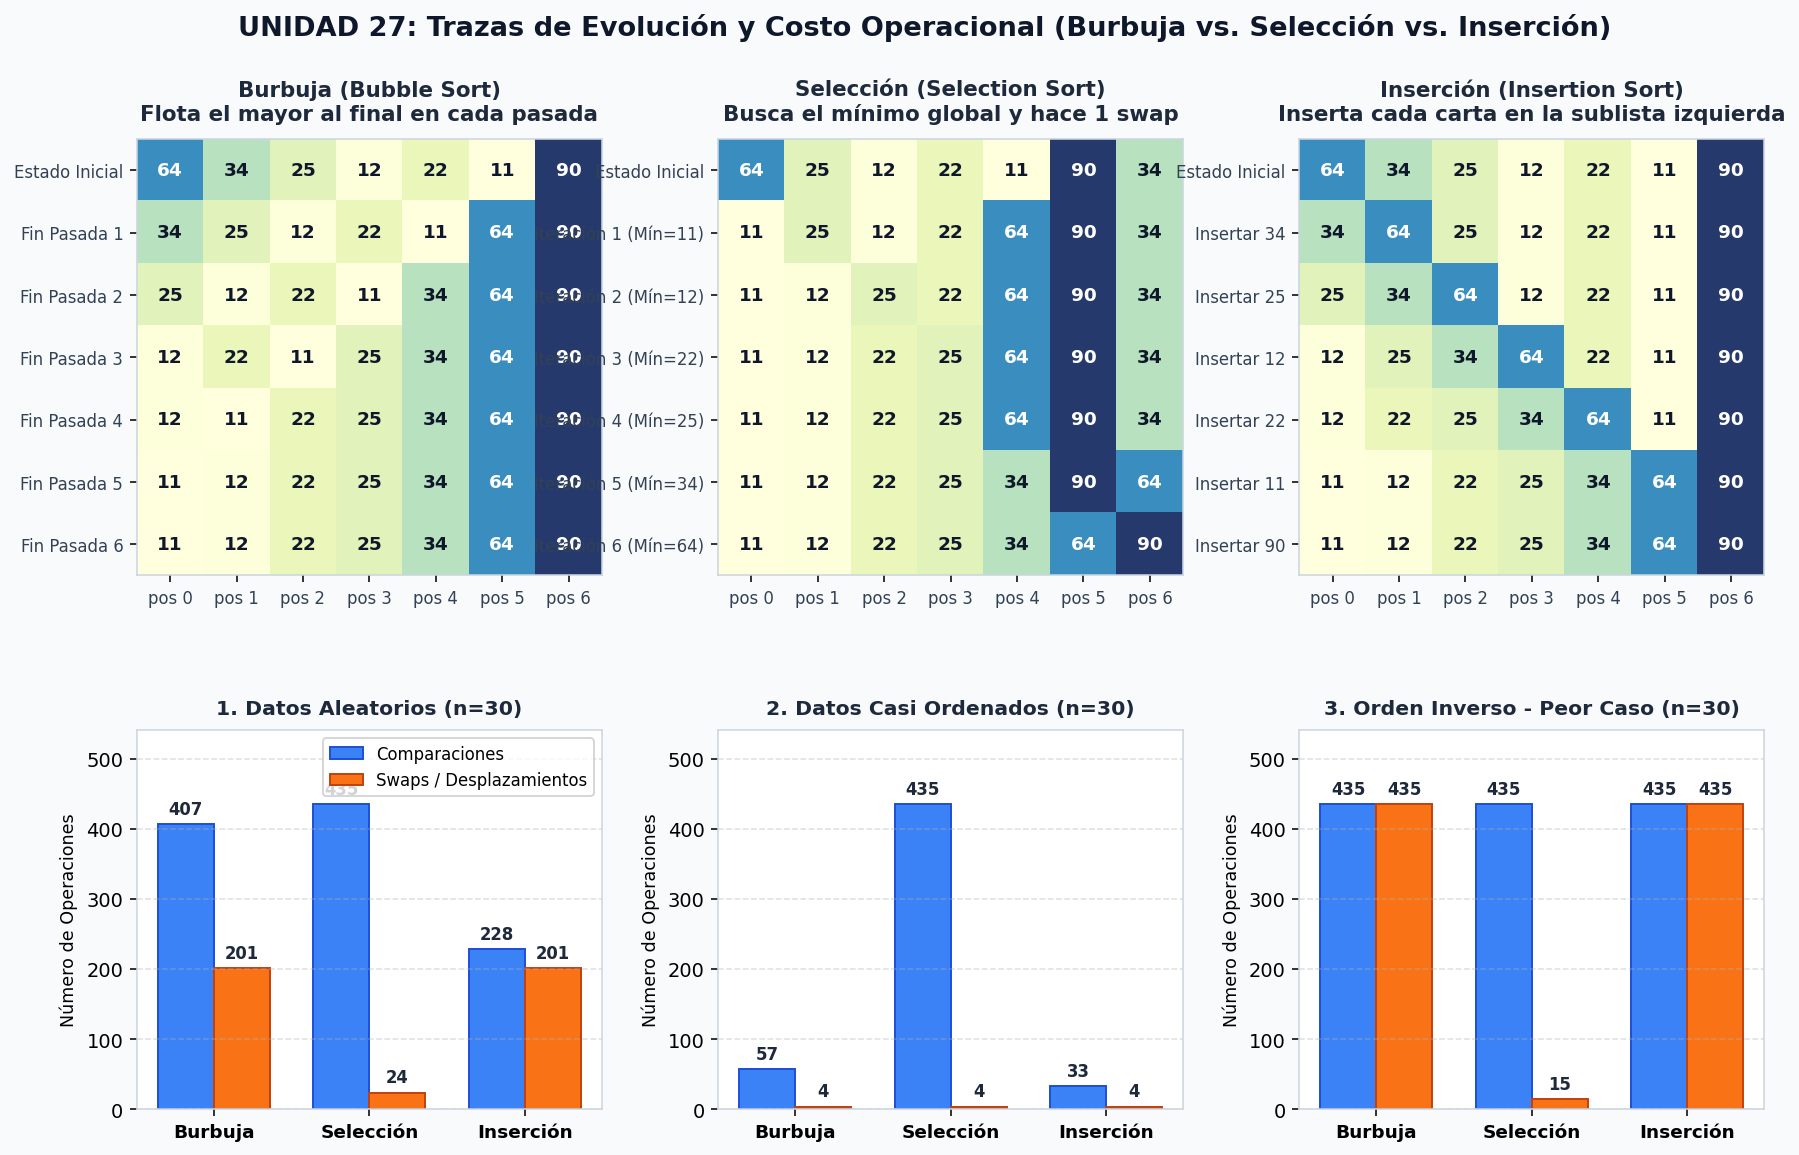

In [ ]:
# --- GRÁFICA 1: Evolución Paso a Paso y Comparativa Operacional de la Unidad 27 ---
fig = plt.figure(figsize=(15, 9), facecolor='#F8FAFC')
gs = fig.add_gridspec(2, 3, height_ratios=[1.15, 1], hspace=0.38, wspace=0.25)

# Colores semánticos
COLOR_BASE = '#94A3B8'
COLOR_ORDENADO = '#2563EB'
COLOR_ACTIVO = '#F59E0B'
COLOR_VERDE = '#10B981'

# Paneles Superiores: Evolución de estados (Mapa de calor / barras de progreso por iteración)
historiales_u27 = [
    ("Burbuja (Bubble Sort)\nFlota el mayor al final en cada pasada", hist_b, '#3B82F6'),
    ("Selección (Selection Sort)\nBusca el mínimo global y hace 1 swap", hist_s, '#8B5CF6'),
    ("Inserción (Insertion Sort)\nInserta cada carta en la sublista izquierda", hist_i, '#10B981')
]

for col_idx, (titulo, hist, color_tema) in enumerate(historiales_u27):
    ax = fig.add_subplot(gs[0, col_idx])
    ax.set_facecolor('#FFFFFF')
    matriz = np.array([paso[1] for paso in hist])
    etiquetas_y = [paso[0] for paso in hist]

    im = ax.imshow(matriz, cmap='YlGnBu', aspect='auto', alpha=0.88)
    ax.set_title(titulo, fontsize=11, fontweight='bold', color='#1E293B', pad=10)
    ax.set_yticks(range(len(etiquetas_y)))
    ax.set_yticklabels(etiquetas_y, fontsize=8.5, color='#334155')
    ax.set_xticks(range(matriz.shape[1]))
    ax.set_xticklabels([f"pos {k}" for k in range(matriz.shape[1])], fontsize=8.5, color='#334155')

    # Anotar los números exactos dentro de cada celda para máxima claridad pedagógica
    for r in range(matriz.shape[0]):
        for c in range(matriz.shape[1]):
            val = matriz[r, c]
            color_txt = 'white' if val > 55 else '#0F172A'
            ax.text(c, r, f"{val}", ha='center', va='center', fontweight='bold', fontsize=9.5, color=color_txt)

# Paneles Inferiores: Comparación de Comparaciones y Escrituras en 3 escenarios (n = 30)
random.seed(42)
n_test = 30
escenarios = {
    "1. Datos Aleatorios (n=30)": [random.randint(1, 100) for _ in range(n_test)],
    "2. Datos Casi Ordenados (n=30)": [x if x % 10 != 0 else x + 3 for x in range(1, n_test + 1)],
    "3. Orden Inverso - Peor Caso (n=30)": list(range(n_test, 0, -1))
}

for col_idx, (nombre_esc, datos_esc) in enumerate(escenarios.items()):
    ax = fig.add_subplot(gs[1, col_idx])
    ax.set_facecolor('#FFFFFF')

    _, c_b, m_b, _ = bubble_sort_explicado(datos_esc, verbose=False)
    _, c_s, m_s, _ = selection_sort_explicado(datos_esc, verbose=False)
    _, c_i, m_i, _ = insertion_sort_explicado(datos_esc, verbose=False)

    algos = ['Burbuja', 'Selección', 'Inserción']
    comps = [c_b, c_s, c_i]
    movs = [m_b, m_s, m_i]

    x = np.arange(len(algos))
    width = 0.36
    b1 = ax.bar(x - width/2, comps, width, label='Comparaciones', color='#3B82F6', edgecolor='#1D4ED8')
    b2 = ax.bar(x + width/2, movs, width, label='Swaps / Desplazamientos', color='#F97316', edgecolor='#C2410C')

    ax.set_title(nombre_esc, fontsize=10.5, fontweight='bold', color='#1E293B', pad=8)
    ax.set_xticks(x)
    ax.set_xticklabels(algos, fontsize=9.5, fontweight='bold')
    ax.set_ylabel("Número de Operaciones", fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_ylim(0, max(comps + movs) * 1.22 + 10)

    for bar in list(b1) + list(b2):
        h = int(bar.get_height())
        ax.text(bar.get_x() + bar.get_width()/2, h + max(comps + movs)*0.02,
                f"{h}", ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1E293B')
    if col_idx == 0:
        ax.legend(fontsize=8.5, loc='upper right')

fig.suptitle("UNIDAD 27: Trazas de Evolución y Costo Operacional (Burbuja vs. Selección vs. Inserción)",
             fontsize=14, fontweight='bold', color='#0F172A', y=0.98)
plt.show()

---
# 📗 UNIDAD 28: Ordenamiento por Fusión (*Merge Sort*)
### (*El Paradigma "Divide y Vencerás" con Garantía Matemática $O(n \log n)$*)

Cuando el volumen de datos crece de unos pocos cientos a cientos de miles o millones de registros, los algoritmos cuadráticos $O(n^2)$ de la Unidad 27 se vuelven inviables:
* Para $n = 100,000$, $n^2 = 10,000,000,000$ ($10^{10}$ operaciones $\approx$ varios segundos o minutos).
* En cambio, $n \log_2 n \approx 100,000 \times 16.6 \approx 1,660,000$ operaciones (**¡más de $6,000$ veces más rápido!**).

---

## 28.1 Fundamento Teórico: ¿Cómo Funciona *Merge Sort*?

Diseñado por el pionero de la computación **John von Neumann en 1945**, el **Ordenamiento por Fusión (*Merge Sort*)** aplica el paradigma **Divide y Vencerás (*Divide and Conquer*)** en tres fases claras:

1. **DIVIDIR (*Divide*):** Si el arreglo tiene 0 o 1 elemento, ya está ordenado (caso base). Si tiene 2 o más elementos, calculamos el punto medio `medio = len(arr) // 2` y partimos el arreglo en dos mitades: `izquierda = arr[:medio]` y `derecha = arr[medio:]`.
2. **CONQUISTAR (*Conquer*):** Ordenamos recursivamente la mitad `izquierda` y la mitad `derecha` aplicando *Merge Sort*.
3. **COMBINAR / FUSIONAR (*Merge*):** Mezclamos las dos mitades ya ordenadas en un único arreglo ordenado utilizando la **técnica de dos punteros (`i` y `j`)**, comparando siempre el frente de ambas mitades y tomando el menor (o el de la izquierda en caso de empate, garantizando **estabilidad**).

### 📐 Diagrama Visual del Árbol de División y Fusión
```
                        [ 38, 27, 43, 3, 9, 82, 10 ]
                                     │
                 ┌───────────────────┴───────────────────┐          FASE 1: DIVIDIR
        [ 38, 27, 43, 3 ]                         [ 9, 82, 10 ]     (Hasta llegar a 1 elem)
            │                                           │
      ┌─────┴─────┐                               ┌─────┴─────┐
  [38, 27]     [43, 3]                        [9, 82]       [10]
   ┌──┴──┐     ┌──┴──┐                        ┌──┴──┐         │
 [38]  [27]  [43]   [3]                      [9]  [82]      [10]
   └──┬──┘     └──┬──┘                        └──┬──┘         │
  [27, 38]     [3, 43]                        [9, 82]       [10]    FASE 2: FUSIONAR (MERGE)
      └─────┬─────┘                               └─────┬─────┘     (Comparando frentes con
     [ 3, 27, 38, 43 ]                           [ 9, 10, 82 ]       2 punteros i, j)
                 └───────────────────┬───────────────────┘
                        [ 3, 9, 10, 27, 38, 43, 82 ]
```

### 🧮 Análisis Matemático: ¿Por qué siempre es $O(n \log n)$?
La recurrencia de *Merge Sort* está dada por el Teorema Maestro:
$$T(n) = 2T\left(\frac{n}{2}\right) + O(n)$$
* **Altura del árbol de recursión:** Como dividimos el tamaño $n$ entre 2 en cada nivel, el árbol tiene exactamente $\lceil \log_2(n) \rceil$ niveles.
* **Trabajo por nivel:** En cada nivel del árbol, la función `merge` recorre todos los elementos exactamente una vez, realizando un trabajo lineal $O(n)$.
* **Costo Total:** $(\text{Trabajo por nivel}) \times (\text{Número de niveles}) = O(n) \times O(\log n) = \mathbf{O(n \log n)}$ **en el mejor, promedio y peor caso**.

---

## 28.2 Usos Prácticos en la Programación Moderna y Relevancia Actual

1. **Ordenamiento Estable de Objetos Complejos (E-Commerce, Finanzas, UI):**
   * Cuando un usuario en una tienda online o dashboard financiero ordena primero los productos por **Precio (ascendente)** y luego hace clic en ordenar por **Categoría o Calificación**, necesitamos que dentro de la misma categoría los productos conserven el orden por precio previo. Gracias a la condición `izquierda[i] <= derecha[j]`, *Merge Sort* es **100% estable**.
2. **Ordenamiento Externo (*External Merge Sort*) en Bases de Datos y Big Data:**
   * ¿Qué ocurre cuando debes ordenar un archivo de **500 GB de logs bancarios** en un servidor que solo tiene **16 GB de memoria RAM**? *Quick Sort* no puede hacerlo porque requiere acceso aleatorio en RAM. En cambio, **External Merge Sort** divide el archivo de 500 GB en bloques de 8 GB, los ordena en RAM, los guarda en disco y luego fusiona los bloques leyendo secuencialmente del disco. Así funcionan **Apache Spark, Hadoop MapReduce, PostgreSQL y BigQuery**.
3. **Ordenamiento de Listas Enlazadas (*Linked Lists*):**
   * En una lista enlazada (`struct Node*`), acceder a un índice aleatorio toma $O(n)$, lo que arruina a *Quick Sort*. *Merge Sort* es el algoritmo estándar para listas enlazadas (como `std::list::sort()` en C++), logrando $O(n \log n)$ en tiempo y **$O(1)$ en memoria auxiliar** reasignando punteros.
4. **Cálculo de Inversiones en Sistemas de Recomendación:**
   * En filtrado colaborativo (Netflix, Spotify), medir qué tan similares son los gustos de dos usuarios equivale a contar cuántas inversiones hay entre sus rankings de películas/canciones, lo cual se resuelve en $O(n \log n)$ con una ligera modificación de `merge()`.

In [ ]:
def merge(izquierda, derecha, key=lambda x: x):
    '''
    Combina dos listas ya ordenadas (izquierda y derecha) en una sola lista ordenada.
    Usa `<=` para garantizar ESTABILIDAD (preserva el orden relativo de elementos iguales).
    '''
    resultado = []
    i = j = 0
    comparaciones = 0

    while i < len(izquierda) and j < len(derecha):
        comparaciones += 1
        # El operador <= es la clave de la ESTABILIDAD de Merge Sort
        if key(izquierda[i]) <= key(derecha[j]):
            resultado.append(izquierda[i])
            i += 1
        else:
            resultado.append(derecha[j])
            j += 1

    # Agregar los elementos restantes de cualquiera de las dos mitades
    resultado.extend(izquierda[i:])
    resultado.extend(derecha[j:])
    return resultado, comparaciones


def merge_sort(arr, key=lambda x: x, nivel=0, registro_niveles=None):
    '''
    Implementación completa y recursiva de Ordenamiento por Fusión (Merge Sort).
    Registra cada división y fusión para su análisis didáctico.
    '''
    if registro_niveles is not None:
        registro_niveles.append(("DIVIDIR", nivel, list(arr)))

    # Caso base: una lista de 0 o 1 elemento ya está ordenada por definición
    if len(arr) <= 1:
        return list(arr), 0

    medio = len(arr) // 2

    # 1. DIVIDIR y 2. CONQUISTAR recursivamente
    izq_ordenada, comp_izq = merge_sort(arr[:medio], key=key, nivel=nivel + 1, registro_niveles=registro_niveles)
    der_ordenada, comp_der = merge_sort(arr[medio:], key=key, nivel=nivel + 1, registro_niveles=registro_niveles)

    # 3. COMBINAR (FUSIONAR) ambas mitades ordenadas
    fusionada, comp_merge = merge(izq_ordenada, der_ordenada, key=key)

    if registro_niveles is not None:
        registro_niveles.append(("FUSIONAR", nivel, list(fusionada)))

    return fusionada, (comp_izq + comp_der + comp_merge)


# --- EJEMPLO PRÁCTICO 1: Traza de División y Fusión ---
print("=" * 76)
print("EJEMPLO 1 (UNIDAD 28): Árbol de Ejecución de Merge Sort")
print("=" * 76)
datos_u28 = [38, 27, 43, 3, 9, 82, 10]
traza_u28 = []
ordenado_u28, total_comp_u28 = merge_sort(datos_u28, registro_niveles=traza_u28)

for accion, niv, sublista in traza_u28:
    sangria = "    " * niv
    icono = "✂️" if accion == "DIVIDIR" else "🔗"
    print(f"{sangria}{icono} [Nivel {niv}] {accion:8s}: {sublista}")

print(f"\n✅ Resultado Final Ordenado: {ordenado_u28} (Total comparaciones: {total_comp_u28})")

# --- EJEMPLO PRÁCTICO 2: Ordenamiento Estable Multicriterio en E-Commerce ---
print("\n" + "=" * 76)
print("EJEMPLO 2 (UNIDAD 28): Demostración de ESTABILIDAD en Transacciones Reales")
print("=" * 76)
transacciones = [
    {"id": "TX-01", "cliente": "Ana",    "monto": 250, "prioridad": 2},
    {"id": "TX-02", "cliente": "Carlos", "monto": 120, "prioridad": 1},
    {"id": "TX-03", "cliente": "Beatriz","monto": 500, "prioridad": 2},
    {"id": "TX-04", "cliente": "David",  "monto": 90,  "prioridad": 1},
    {"id": "TX-05", "cliente": "Elena",  "monto": 310, "prioridad": 1},
]

# Paso 1: Ordenar por monto de mayor a menor (usando clave negativa)
por_monto, _ = merge_sort(transacciones, key=lambda x: -x["monto"])
# Paso 2: Ordenar por prioridad (1 = Alta, 2 = Normal). Como Merge Sort es ESTABLE,
# dentro de la misma prioridad los clientes conservan su orden de mayor a menor monto.
por_prioridad_y_monto, _ = merge_sort(por_monto, key=lambda x: x["prioridad"])

print("Transacciones ordenadas por Prioridad (1->2) preservando el orden por Monto Mayor:")
for tx in por_prioridad_y_monto:
    print(f"  Prioridad {tx['prioridad']} | Monto: ${tx['monto']:3d} | {tx['id']} ({tx['cliente']})")

EJEMPLO 1 (UNIDAD 28): Árbol de Ejecución de Merge Sort
✂️ [Nivel 0] DIVIDIR : [38, 27, 43, 3, 9, 82, 10]
    ✂️ [Nivel 1] DIVIDIR : [38, 27, 43]
        ✂️ [Nivel 2] DIVIDIR : [38]
        ✂️ [Nivel 2] DIVIDIR : [27, 43]
            ✂️ [Nivel 3] DIVIDIR : [27]
            ✂️ [Nivel 3] DIVIDIR : [43]
        🔗 [Nivel 2] FUSIONAR: [27, 43]
    🔗 [Nivel 1] FUSIONAR: [27, 38, 43]
    ✂️ [Nivel 1] DIVIDIR : [3, 9, 82, 10]
        ✂️ [Nivel 2] DIVIDIR : [3, 9]
            ✂️ [Nivel 3] DIVIDIR : [3]
            ✂️ [Nivel 3] DIVIDIR : [9]
        🔗 [Nivel 2] FUSIONAR: [3, 9]
        ✂️ [Nivel 2] DIVIDIR : [82, 10]
            ✂️ [Nivel 3] DIVIDIR : [82]
            ✂️ [Nivel 3] DIVIDIR : [10]
        🔗 [Nivel 2] FUSIONAR: [10, 82]
    🔗 [Nivel 1] FUSIONAR: [3, 9, 10, 82]
🔗 [Nivel 0] FUSIONAR: [3, 9, 10, 27, 38, 43, 82]

✅ Resultado Final Ordenado: [3, 9, 10, 27, 38, 43, 82] (Total comparaciones: 13)

EJEMPLO 2 (UNIDAD 28): Demostración de ESTABILIDAD en Transacciones Reales
Transacciones orde

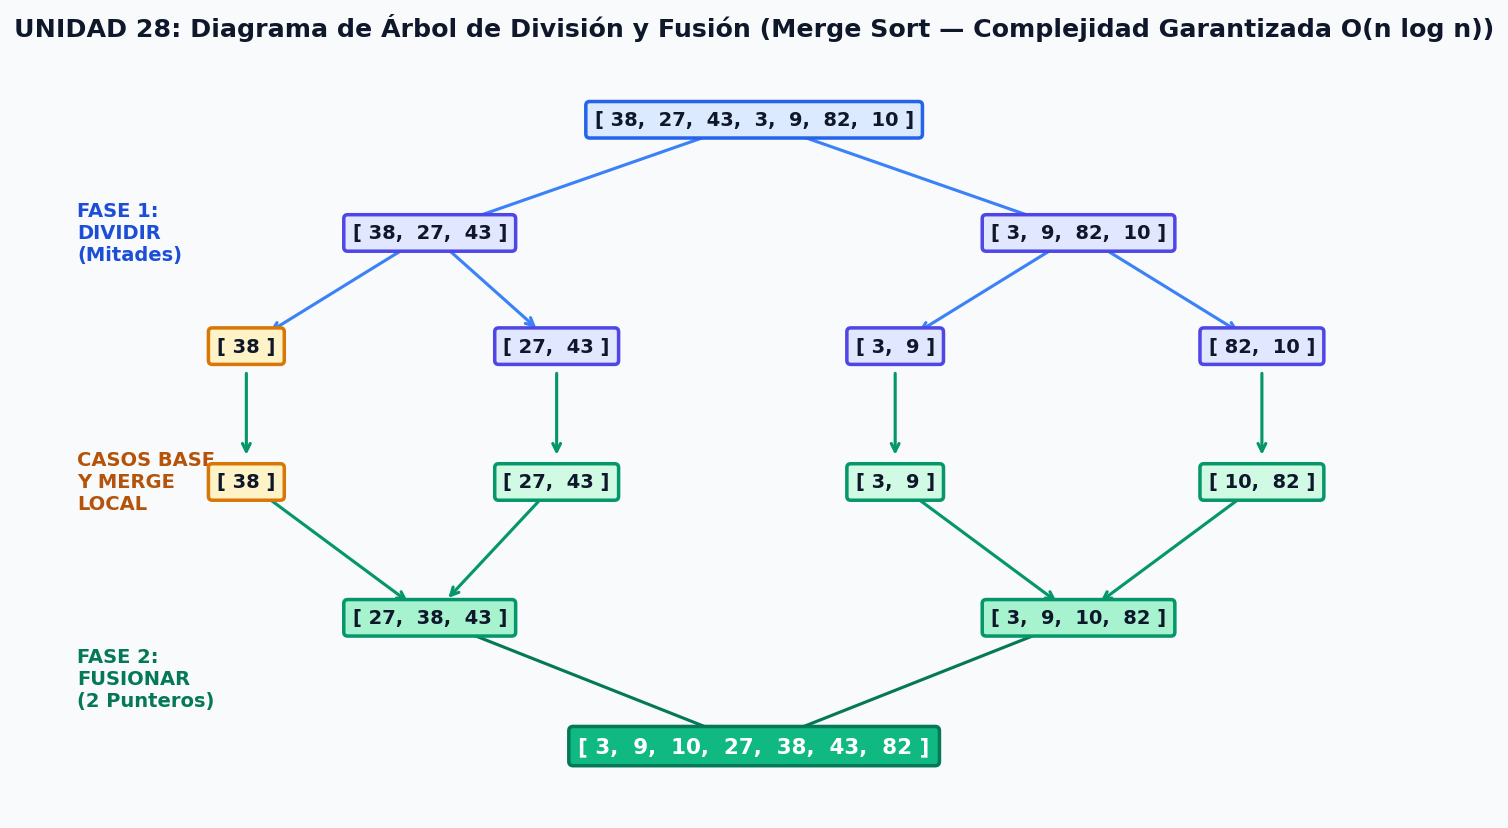

In [ ]:
# --- GRÁFICA 2: Diagrama Visual del Árbol Divide y Vencerás de Merge Sort ---
fig, ax = plt.subplots(figsize=(13, 7), facecolor='#F8FAFC')
ax.set_facecolor('#FFFFFF')
ax.axis('off')

def dibujar_caja(ax, x, y, texto, bg_color, border_color, text_color='#0F172A', fontsize=10):
    bbox_props = dict(boxstyle="round,pad=0.45,rounding_size=0.2", fc=bg_color, ec=border_color, lw=1.8)
    ax.text(x, y, texto, ha="center", va="center", fontsize=fontsize, fontweight='bold',
            color=text_color, bbox=bbox_props, zorder=4)

def dibujar_flecha(ax, x1, y1, x2, y2, color='#64748B'):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color=color, lw=1.6, shrinkA=14, shrinkB=14), zorder=2)

# Coordenadas por niveles (Y de arriba hacia abajo: División -> Caso Base -> Fusión)
# Nivel 0: Original
dibujar_caja(ax, 0.50, 0.92, "[ 38,  27,  43,  3,  9,  82,  10 ]", "#DBEAFE", "#2563EB")

# Nivel 1: Primera división
dibujar_caja(ax, 0.27, 0.77, "[ 38,  27,  43 ]", "#E0E7FF", "#4F46E5")
dibujar_caja(ax, 0.73, 0.77, "[ 3,  9,  82,  10 ]", "#E0E7FF", "#4F46E5")
dibujar_flecha(ax, 0.50, 0.92, 0.27, 0.77, "#3B82F6")
dibujar_flecha(ax, 0.50, 0.92, 0.73, 0.77, "#3B82F6")

# Nivel 2: Segunda división
dibujar_caja(ax, 0.14, 0.62, "[ 38 ]", "#FEF3C7", "#D97706")
dibujar_caja(ax, 0.36, 0.62, "[ 27,  43 ]", "#E0E7FF", "#4F46E5")
dibujar_caja(ax, 0.60, 0.62, "[ 3,  9 ]", "#E0E7FF", "#4F46E5")
dibujar_caja(ax, 0.86, 0.62, "[ 82,  10 ]", "#E0E7FF", "#4F46E5")
for x_orig, x_dest in [(0.27, 0.14), (0.27, 0.36), (0.73, 0.60), (0.73, 0.86)]:
    dibujar_flecha(ax, x_orig, 0.77, x_dest, 0.62, "#3B82F6")

# Nivel 3: Hojas unitarias y primeras fusiones
dibujar_caja(ax, 0.14, 0.44, "[ 38 ]", "#FEF3C7", "#D97706")
dibujar_caja(ax, 0.36, 0.44, "[ 27,  43 ]", "#D1FAE5", "#059669")
dibujar_caja(ax, 0.60, 0.44, "[ 3,  9 ]", "#D1FAE5", "#059669")
dibujar_caja(ax, 0.86, 0.44, "[ 10,  82 ]", "#D1FAE5", "#059669")
for x_pos in [0.14, 0.36, 0.60, 0.86]:
    dibujar_flecha(ax, x_pos, 0.62, x_pos, 0.44, "#059669")

# Nivel 4: Fusión de mitades
dibujar_caja(ax, 0.27, 0.26, "[ 27,  38,  43 ]", "#A7F3D0", "#059669")
dibujar_caja(ax, 0.73, 0.26, "[ 3,  9,  10,  82 ]", "#A7F3D0", "#059669")
for x_orig, x_dest in [(0.14, 0.27), (0.36, 0.27), (0.60, 0.73), (0.86, 0.73)]:
    dibujar_flecha(ax, x_orig, 0.44, x_dest, 0.26, "#059669")

# Nivel 5: Resultado final fusionado
dibujar_caja(ax, 0.50, 0.09, "[ 3,  9,  10,  27,  38,  43,  82 ]", "#10B981", "#047857", text_color="white", fontsize=11)
dibujar_flecha(ax, 0.27, 0.26, 0.50, 0.09, "#047857")
dibujar_flecha(ax, 0.73, 0.26, 0.50, 0.09, "#047857")

# Etiquetas laterales de fases
ax.text(0.02, 0.77, "FASE 1:\nDIVIDIR\n(Mitades)", fontsize=10, fontweight='bold', color='#1D4ED8', va='center')
ax.text(0.02, 0.44, "CASOS BASE\nY MERGE\nLOCAL", fontsize=10, fontweight='bold', color='#B45309', va='center')
ax.text(0.02, 0.18, "FASE 2:\nFUSIONAR\n(2 Punteros)", fontsize=10, fontweight='bold', color='#047857', va='center')

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("UNIDAD 28: Diagrama de Árbol de División y Fusión (Merge Sort — Complejidad Garantizada O(n log n))",
             fontsize=13, fontweight='bold', color='#0F172A', pad=12)
plt.show()

---
# 📙 UNIDAD 29: Ordenamiento Rápido (*Quick Sort*)
### (*El Estándar de Velocidad In-Place en Memoria Caché*)

Creado por el científico británico **Tony Hoare en 1959** (ganador del Premio Turing), el **Ordenamiento Rápido (*Quick Sort*)** también pertenece al paradigma **Divide y Vencerás**, pero con una filosofía radicalmente opuesta a *Merge Sort*:
* En **Merge Sort**, dividir el arreglo es trivial (cortar a la mitad) y todo el trabajo pesado ocurre al final durante la **fusión (`merge`)**.
* En **Quick Sort**, todo el trabajo pesado ocurre al principio durante la **partición (`partition`)**, de modo que cuando las dos mitades terminan de ordenarse recursivamente, **¡no hace falta fusionar nada!** El arreglo ya queda ordenado *in-place*.

---

## 29.1 El Corazón de *Quick Sort*: La Operación de Partición (*Partition*)

El algoritmo funciona en tres pasos:
1. **Elegir un Pivote (`pivot`):** Seleccionamos un elemento del subarreglo (puede ser el último elemento, el primero, uno aleatorio o la **mediana de tres** entre el primero, central y último).
2. **Particionar (*Partitioning*):** Reorganizamos el subarreglo *in-place* de tal manera que:
   * Todos los elementos **menores o iguales al pivote** queden a su **izquierda**.
   * El **pivote** quede colocado en su **posición definitiva exacta** (índice `p`).
   * Todos los elementos **mayores que el pivote** queden a su **derecha**.
3. **Recursión sobre los lados:** Aplicamos *Quick Sort* recursivamente al subarreglo izquierdo (`low .. p-1`) y al subarreglo derecho (`p+1 .. high`).

### 📐 Traza Visual de la Partición de Lomuto (Arreglo: `[10, 80, 30, 90, 40, 50, 70]`, Pivote = `70`)
Mantenemos un puntero `i` que marca la frontera de los elementos menores o iguales al pivote, y un puntero explorador `j` que recorre el arreglo:
```
Inicio:  i = -1, Pivote = 70 (último elemento)
         [ 10, 80, 30, 90, 40, 50 | 70 ]

j=0 (val=10): 10 <= 70 -> i sube a 0, swap(arr[0], arr[0]) -> [ 10, 80, 30, 90, 40, 50 | 70 ]
j=1 (val=80): 80 >  70 -> No hace nada                     -> [ 10, 80, 30, 90, 40, 50 | 70 ]
j=2 (val=30): 30 <= 70 -> i sube a 1, swap(arr[1], arr[2]) -> [ 10, 30, 80, 90, 40, 50 | 70 ]
j=3 (val=90): 90 >  70 -> No hace nada                     -> [ 10, 30, 80, 90, 40, 50 | 70 ]
j=4 (val=40): 40 <= 70 -> i sube a 2, swap(arr[2], arr[4]) -> [ 10, 30, 40, 90, 80, 50 | 70 ]
j=5 (val=50): 50 <= 70 -> i sube a 3, swap(arr[3], arr[5]) -> [ 10, 30, 40, 50, 80, 90 | 70 ]

Paso Final de Partición: Colocamos el pivote en `i + 1` (índice 4), swap(arr[4], arr[6]):
         [ 10, 30, 40, 50, | 70 |, 90, 80 ]
           ^^^^^^^^^^^^^^    ^^    ^^^^^^
            Menores (<=70)  PIVOTE Mayores (>70)
                            FIJO!
```

---

## 29.2 El Dilema del Pivote: Caso Promedio $O(n \log n)$ vs. Peor Caso $O(n^2)$

* **Mejor Caso y Caso Promedio ($O(n \log n)$):** El pivote divide el arreglo en dos partes razonablemente equilibradas (incluso una división $90\% - 10\%$ mantiene una profundidad logarítmica $O(\log n)$).
* **Peor Caso ($O(n^2)$):** Ocurre cuando elegimos ingenuamente el primer o último elemento como pivote y el arreglo **ya está ordenado** (o en orden inverso). En cada paso, una mitad queda con $n-1$ elementos y la otra con $0$ elementos, degenerando en un árbol de altura $n$.
* **Solución en Ingeniería de Software Moderna:**
  1. **Pivote por Mediana de Tres (*Median-of-Three*):** Tomar la mediana entre `arr[low]`, `arr[mid]` y `arr[high]`. Si el arreglo ya viene ordenado, elige automáticamente el elemento central, convirtiendo el peor caso en el **mejor caso exacto**.
  2. **Pivote Aleatorio (*Randomized QuickSort*):** Elegir un índice al azar elimina cualquier patrón adversario en los datos de entrada.

---

## 29.3 Usos Prácticos en la Programación Moderna y Por Qué es Crucial

1. **Librerías Estándar de Alto Rendimiento (`C++ std::sort`, `Rust sort_unstable`, `Go slices.Sort`):**
   * En la práctica, *Quick Sort* suele ser **entre 1.5x y 3x más rápido que *Merge Sort*** para arreglos en memoria RAM porque opera *in-place* (no reserva ni copia arreglos temporales en el *heap*) y recorre posiciones contiguas de memoria, maximizando los aciertos en la **caché L1/L2 de la CPU** (*cache locality*).
2. **Algoritmo *QuickSelect* (Búsqueda de Percentiles y Medianas en $O(n)$):**
   * Usando exactamente la misma función `partition` de *Quick Sort*, el algoritmo **QuickSelect** (como `numpy.partition` o `std::nth_element`) encuentra la mediana, el percentil 95 de latencia de un servidor o el *Top-K* de productos más vendidos en **tiempo lineal promedio $O(n)$** sin necesidad de ordenar todo el arreglo.
3. **Sistemas Embebidos y Videojuegos en Tiempo Real:**
   * Donde la asignación dinámica de memoria (`malloc` / `new`) está restringida para evitar fragmentación de RAM o pausas del recolector de basura (*Garbage Collector*).

In [ ]:
def particion_mediana_de_tres(arr, low, high, trazas=None):
    '''
    Partición in-place optimizada con selección de pivote por 'Mediana de Tres'
    (entre arr[low], arr[mid] y arr[high]) para evitar el peor caso O(n^2)
    cuando los datos ya vienen ordenados o inversamente ordenados.
    '''
    mid = (low + high) // 2
    # Ordenar low, mid, high entre sí para que la mediana quede en mid
    if arr[low] > arr[mid]:
        arr[low], arr[mid] = arr[mid], arr[low]
    if arr[low] > arr[high]:
        arr[low], arr[high] = arr[high], arr[low]
    if arr[mid] > arr[high]:
        arr[mid], arr[high] = arr[high], arr[mid]

    # Colocar la mediana en la posición high para usar el esquema de Lomuto estándar
    arr[mid], arr[high] = arr[high], arr[mid]
    pivote = arr[high]

    i = low - 1
    comparaciones = 3
    intercambios = 1

    for j in range(low, high):
        comparaciones += 1
        if arr[j] <= pivote:
            i += 1
            arr[i], arr[j] = arr[j], arr[i]
            intercambios += 1

    # Colocar el pivote en su posición final definitiva (i + 1)
    arr[i + 1], arr[high] = arr[high], arr[i + 1]
    intercambios += 1
    pos_pivote = i + 1

    if trazas is not None:
        trazas.append({
            "rango": (low, high),
            "pivote_val": pivote,
            "pivote_idx": pos_pivote,
            "estado": arr.copy()
        })

    return pos_pivote, comparaciones, intercambios


def quick_sort_in_place(arr, low=0, high=None, trazas=None):
    '''
    Implementación in-place de Quick Sort con Mediana de Tres.
    '''
    if high is None:
        high = len(arr) - 1

    if low < high:
        p_idx, comp_p, swap_p = particion_mediana_de_tres(arr, low, high, trazas=trazas)
        c_izq, s_izq = quick_sort_in_place(arr, low, p_idx - 1, trazas=trazas)
        c_der, s_der = quick_sort_in_place(arr, p_idx + 1, high, trazas=trazas)
        return (comp_p + c_izq + c_der), (swap_p + s_izq + s_der)
    return 0, 0


# --- EJEMPLO PRÁCTICO 1: Traza de Particiones de Quick Sort ---
print("=" * 76)
print("EJEMPLO 1 (UNIDAD 29): Traza de Particiones In-Place de Quick Sort")
print("=" * 76)
datos_u29 = [45, 20, 80, 10, 60, 90, 30, 70, 50]
copia_u29 = datos_u29.copy()
trazas_q = []

print(f"Arreglo inicial: {copia_u29}\n")
comp_q, swap_q = quick_sort_in_place(copia_u29, trazas=trazas_q)

for idx, t in enumerate(trazas_q, 1):
    l, h = t["rango"]
    p_i = t["pivote_idx"]
    p_v = t["pivote_val"]
    vista = [f"[{x}]" if k == p_i else str(x) for k, x in enumerate(t["estado"])]
    print(f"  Partición {idx} (rango {l}..{h}): Pivote={p_v:2d} fijo en pos {p_i} -> {' '.join(vista)}")

print(f"\n✅ Resultado Final Ordenado: {copia_u29}")
print(f"Total comparaciones: {comp_q} | Total intercambios in-place: {swap_q}")

# --- EJEMPLO PRÁCTICO 2: QuickSelect para encontrar la Mediana y Percentil en O(n) ---
def quick_select_k(arr, k):
    '''Encuentra el k-ésimo elemento menor en tiempo lineal promedio O(n) usando partición de QuickSort.'''
    datos = arr.copy()
    low, high = 0, len(datos) - 1
    while low <= high:
        p_idx, _, _ = particion_mediana_de_tres(datos, low, high)
        if p_idx == k:
            return datos[p_idx]
        elif k < p_idx:
            high = p_idx - 1
        else:
            low = p_idx + 1
    return datos[low]

latencias_ms = [120, 45, 310, 28, 52, 60, 195, 48, 55, 75, 42]
mediana_latencia = quick_select_k(latencias_ms, len(latencias_ms) // 2)
print("\n" + "=" * 76)
print("EJEMPLO 2 (UNIDAD 29): Aplicación Moderna — QuickSelect para Mediana de Latencia")
print("=" * 76)
print(f"Latencias de red capturadas (ms): {latencias_ms}")
print(f"Mediana exacta calculada en O(n) sin ordenar todo el arreglo: {mediana_latencia} ms")

EJEMPLO 1 (UNIDAD 29): Traza de Particiones In-Place de Quick Sort
Arreglo inicial: [45, 20, 80, 10, 60, 90, 30, 70, 50]

  Partición 1 (rango 0..8): Pivote=50 fijo en pos 4 -> 45 20 10 30 [50] 90 80 70 60
  Partición 2 (rango 0..3): Pivote=30 fijo en pos 2 -> 20 10 [30] 45 50 90 80 70 60
  Partición 3 (rango 0..1): Pivote=10 fijo en pos 0 -> [10] 20 30 45 50 90 80 70 60
  Partición 4 (rango 5..8): Pivote=80 fijo en pos 7 -> 10 20 30 45 50 60 70 [80] 90
  Partición 5 (rango 5..6): Pivote=60 fijo en pos 5 -> 10 20 30 45 50 [60] 70 80 90

✅ Resultado Final Ordenado: [10, 20, 30, 45, 50, 60, 70, 80, 90]
Total comparaciones: 31 | Total intercambios in-place: 18

EJEMPLO 2 (UNIDAD 29): Aplicación Moderna — QuickSelect para Mediana de Latencia
Latencias de red capturadas (ms): [120, 45, 310, 28, 52, 60, 195, 48, 55, 75, 42]
Mediana exacta calculada en O(n) sin ordenar todo el arreglo: 55 ms


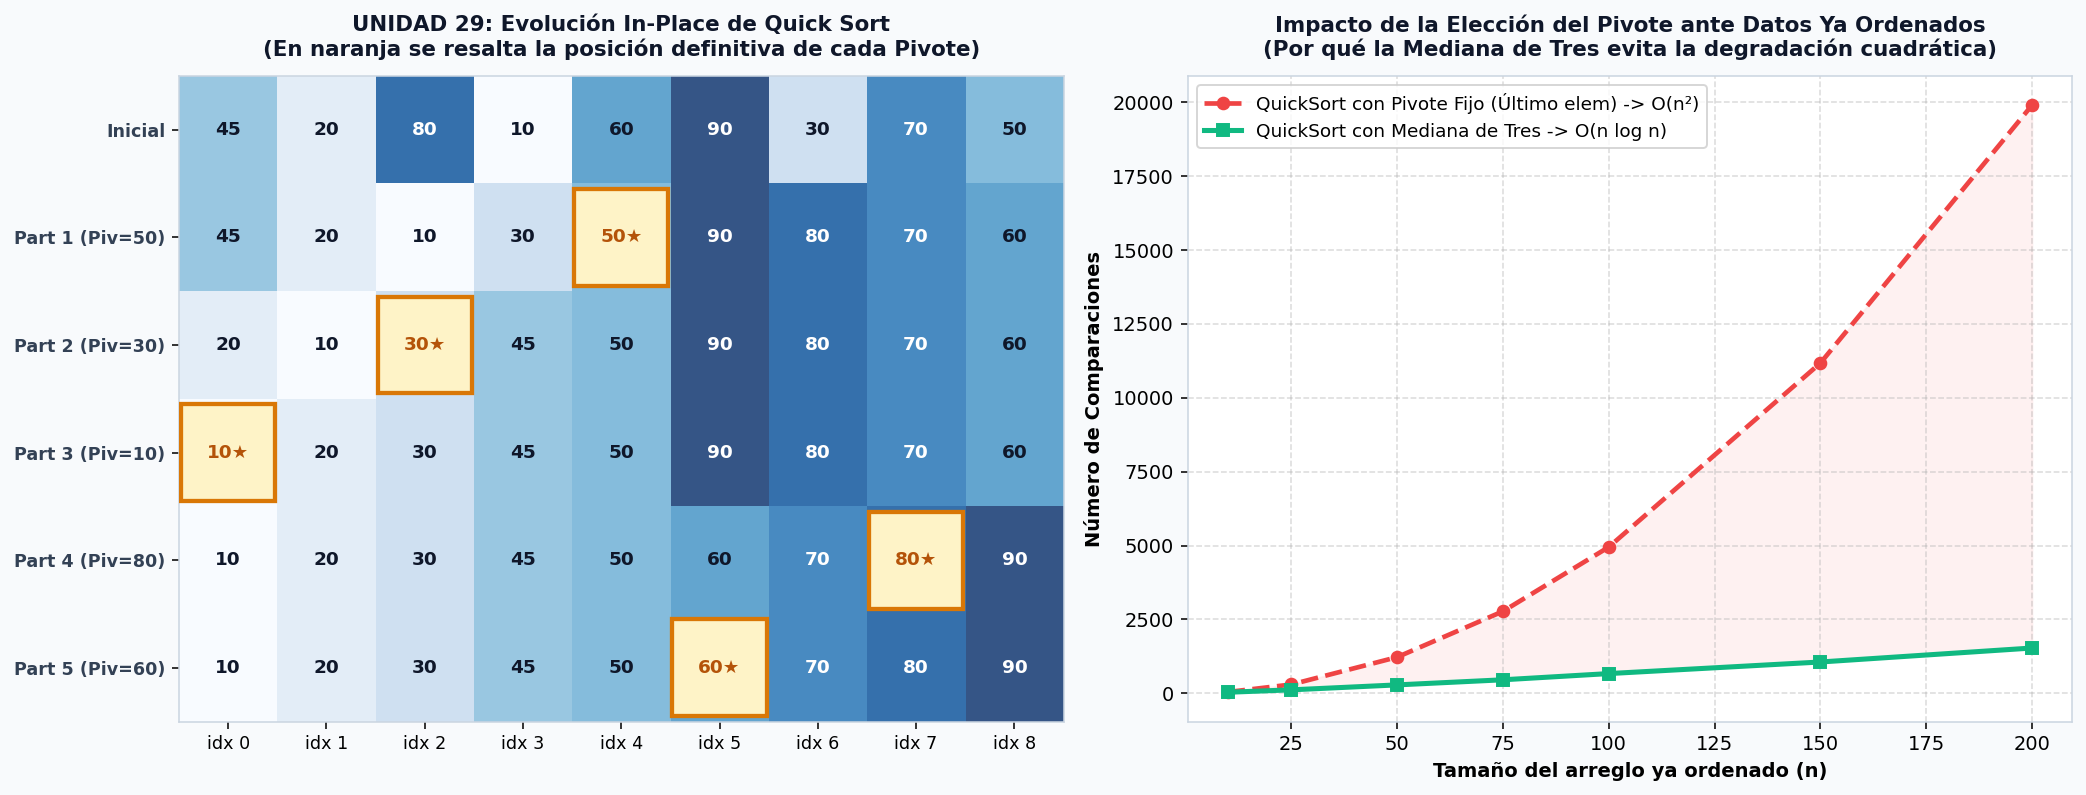

In [ ]:
# --- GRÁFICA 3: Visualización de la Partición de QuickSort y Comparativa de Pivotes ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8), facecolor='#F8FAFC')

# Panel Izquierdo: Visualización del estado del arreglo en cada partición de QuickSort
ax1.set_facecolor('#FFFFFF')
estados_matriz = np.array([datos_u29] + [t["estado"] for t in trazas_q])
etiquetas_q = ["Inicial"] + [f"Part {i+1} (Piv={t['pivote_val']})" for i, t in enumerate(trazas_q)]

im1 = ax1.imshow(estados_matriz, cmap='Blues', aspect='auto', alpha=0.82)
ax1.set_title("UNIDAD 29: Evolución In-Place de Quick Sort\n(En naranja se resalta la posición definitiva de cada Pivote)",
              fontsize=11, fontweight='bold', color='#0F172A', pad=10)
ax1.set_yticks(range(len(etiquetas_q)))
ax1.set_yticklabels(etiquetas_q, fontsize=9, fontweight='bold', color='#334155')
ax1.set_xticks(range( len(datos_u29) ))
ax1.set_xticklabels([f"idx {k}" for k in range(len(datos_u29))], fontsize=9)

pivotes_fijos_acumulados = set()
for r in range(estados_matriz.shape[0]):
    if r > 0:
        pivotes_fijos_acumulados.add(trazas_q[r - 1]["pivote_idx"])
    for c in range(estados_matriz.shape[1]):
        val = estados_matriz[r, c]
        if r > 0 and c == trazas_q[r - 1]["pivote_idx"]:
            rect = patches.Rectangle((c - 0.48, r - 0.45), 0.96, 0.90, linewidth=2.2,
                                     edgecolor='#D97706', facecolor='#FEF3C7', zorder=3)
            ax1.add_patch(rect)
            ax1.text(c, r, f"{val}★", ha='center', va='center', fontweight='bold', fontsize=9.5, color='#B45309', zorder=4)
        else:
            color_t = 'white' if val > 60 else '#0F172A'
            ax1.text(c, r, f"{val}", ha='center', va='center', fontweight='bold', fontsize=9.5, color=color_t, zorder=4)

# Panel Derecho: Comparación de Comparaciones entre Pivote Fijo (Peor caso O(n^2)) vs Mediana de Tres (O(n log n))
ax2.set_facecolor('#FFFFFF')
tamanos_piv = [10, 25, 50, 75, 100, 150, 200]
comp_pivote_fijo_ordenado = [n * (n - 1) // 2 for n in tamanos_piv]  # Peor caso exacto en lista ya ordenada
comp_mediana_tres_ordenado = []

for n_p in tamanos_piv:
    arr_ord = list(range(1, n_p + 1))
    c_m3, _ = quick_sort_in_place(arr_ord)
    comp_mediana_tres_ordenado.append(c_m3)

ax2.plot(tamanos_piv, comp_pivote_fijo_ordenado, 'o--', color='#EF4444', lw=2.4,
         label='QuickSort con Pivote Fijo (Último elem) -> O(n²)')
ax2.plot(tamanos_piv, comp_mediana_tres_ordenado, 's-', color='#10B981', lw=2.6,
         label='QuickSort con Mediana de Tres -> O(n log n)')
ax2.fill_between(tamanos_piv, comp_mediana_tres_ordenado, comp_pivote_fijo_ordenado, color='#FEE2E2', alpha=0.45)

ax2.set_title("Impacto de la Elección del Pivote ante Datos Ya Ordenados\n(Por qué la Mediana de Tres evita la degradación cuadrática)",
              fontsize=11, fontweight='bold', color='#0F172A', pad=10)
ax2.set_xlabel("Tamaño del arreglo ya ordenado (n)", fontsize=10, fontweight='bold')
ax2.set_ylabel("Número de Comparaciones", fontsize=10, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.45)
ax2.legend(fontsize=9.5, loc='upper left')

plt.tight_layout()
plt.show()

---
# 📈 Laboratorio Experimental: Benchmark de Rendimiento y Curvas de Complejidad (Unidades 27, 28 y 29)

Para consolidar el aprendizaje práctico, mediremos experimentalmente el tiempo de ejecución real y el crecimiento de operaciones de los **5 algoritmos estudiados** a medida que aumenta el volumen de datos $n$.

Tamaño (n) |  Burbuja (ms) | Selección (ms) | Inserción (ms) | MergeSort (ms) | QuickSort (ms)
--------------------------------------------------------------------------------------------
        50 |         0.203 |          0.136 |          0.097 |          0.163 |          0.052
       150 |         2.133 |          0.948 |          0.806 |          0.408 |          0.165
       300 |         6.056 |          4.147 |          3.021 |          0.801 |          0.382
       600 |        31.925 |         20.609 |         19.550 |          2.135 |          0.854
       900 |        75.869 |         48.427 |         41.224 |          6.342 |          2.860
      1200 |       133.846 |         75.586 |         67.391 |          7.090 |          1.860


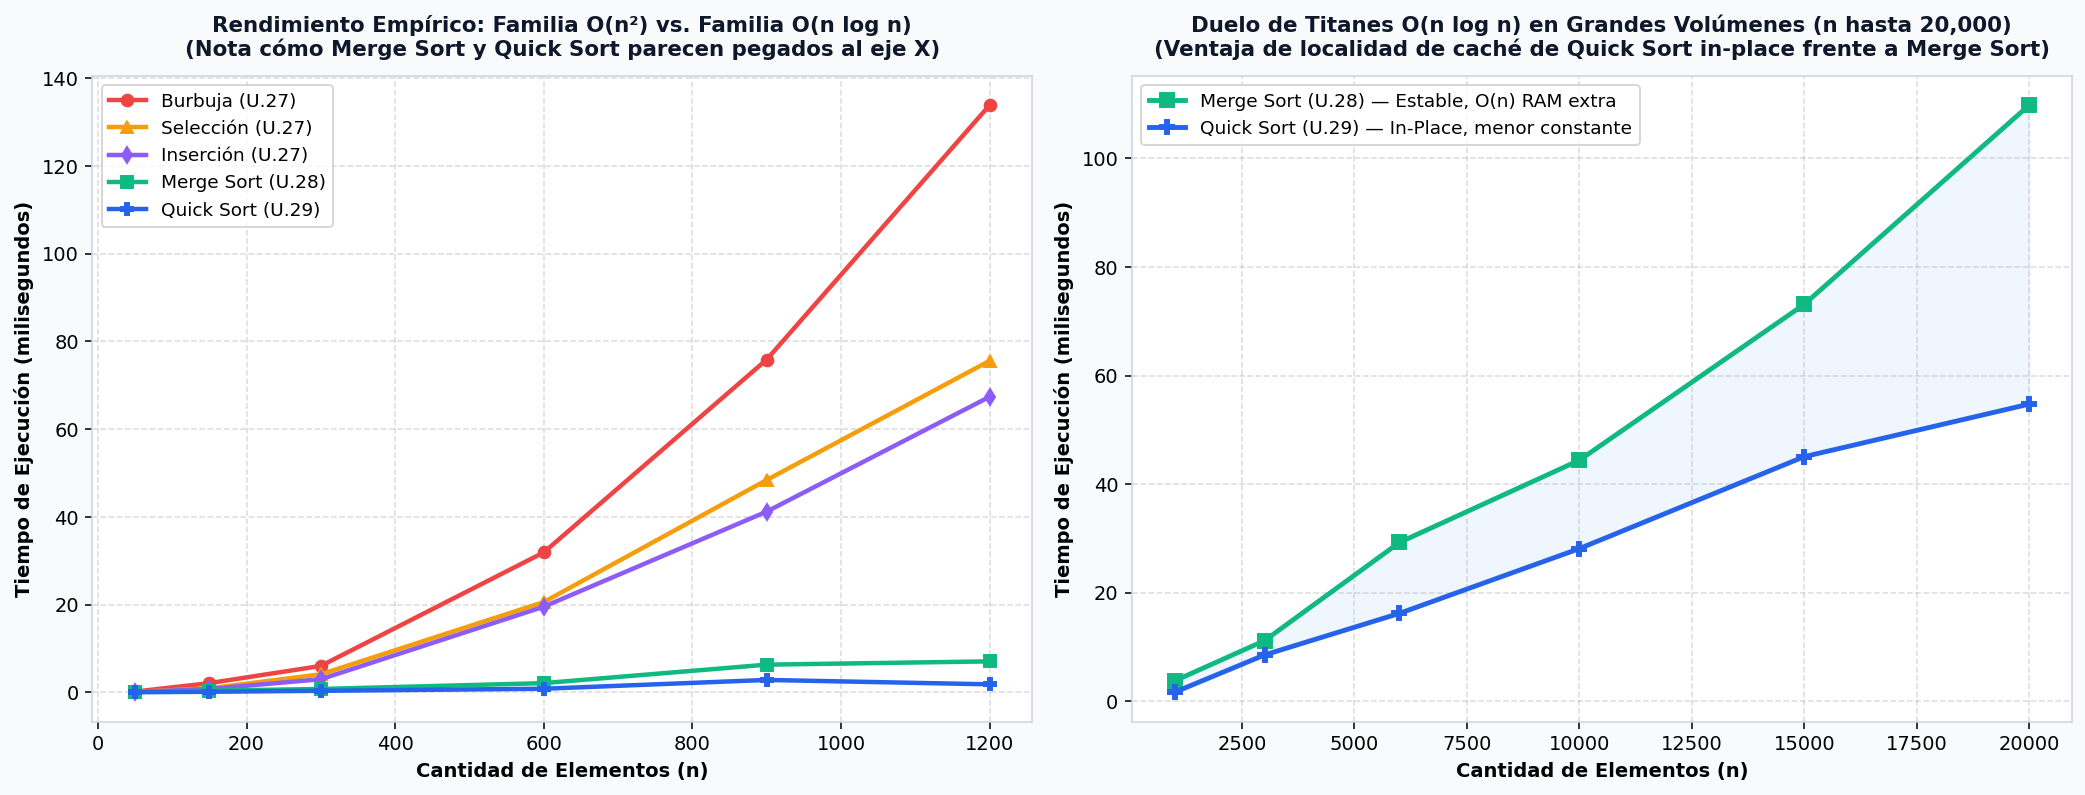

In [ ]:
# --- BENCHMARK REAL DE LOS 5 ALGORITMOS (Unidades 27, 28 y 29) ---
tamanos_bench = [50, 150, 300, 600, 900, 1200]
tiempos = {
    "Burbuja (U.27)": [],
    "Selección (U.27)": [],
    "Inserción (U.27)": [],
    "Merge Sort (U.28)": [],
    "Quick Sort (U.29)": []
}

random.seed(2026)
for n_b in tamanos_bench:
    base_data = [random.randint(1, 100000) for _ in range(n_b)]

    # 1. Burbuja
    t0 = time.perf_counter()
    bubble_sort_explicado(base_data, verbose=False)
    tiempos["Burbuja (U.27)"].append((time.perf_counter() - t0) * 1000)

    # 2. Selección
    t0 = time.perf_counter()
    selection_sort_explicado(base_data, verbose=False)
    tiempos["Selección (U.27)"].append((time.perf_counter() - t0) * 1000)

    # 3. Inserción
    t0 = time.perf_counter()
    insertion_sort_explicado(base_data, verbose=False)
    tiempos["Inserción (U.27)"].append((time.perf_counter() - t0) * 1000)

    # 4. Merge Sort
    t0 = time.perf_counter()
    merge_sort(base_data)
    tiempos["Merge Sort (U.28)"].append((time.perf_counter() - t0) * 1000)

    # 5. Quick Sort
    copia_q = base_data.copy()
    t0 = time.perf_counter()
    quick_sort_in_place(copia_q)
    tiempos["Quick Sort (U.29)"].append((time.perf_counter() - t0) * 1000)

# Imprimir tabla resumen de tiempos en milisegundos
print(f"{'Tamaño (n)':>10} | {'Burbuja (ms)':>13} | {'Selección (ms)':>14} | {'Inserción (ms)':>14} | {'MergeSort (ms)':>14} | {'QuickSort (ms)':>14}")
print("-" * 92)
for idx, n_b in enumerate(tamanos_bench):
    print(f"{n_b:10d} | {tiempos['Burbuja (U.27)'][idx]:13.3f} | {tiempos['Selección (U.27)'][idx]:14.3f} | "
          f"{tiempos['Inserción (U.27)'][idx]:14.3f} | {tiempos['Merge Sort (U.28)'][idx]:14.3f} | {tiempos['Quick Sort (U.29)'][idx]:14.3f}")

# --- GRÁFICA 4: Curvas Empíricas vs. Escalabilidad en Grandes Volúmenes ---
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(15, 5.8), facecolor='#F8FAFC')

# Gráfica Izquierda: Los 5 algoritmos hasta n = 1,200
ax_left.set_facecolor('#FFFFFF')
colores_bench = {
    "Burbuja (U.27)": ("#EF4444", "o-"),
    "Selección (U.27)": ("#F59E0B", "^-"),
    "Inserción (U.27)": ("#8B5CF6", "d-"),
    "Merge Sort (U.28)": ("#10B981", "s-"),
    "Quick Sort (U.29)": ("#2563EB", "P-")
}
for nombre, serie in tiempos.items():
    col, estilo = colores_bench[nombre]
    ax_left.plot(tamanos_bench, serie, estilo, color=col, lw=2.3, markersize=6, label=nombre)

ax_left.set_title("Rendimiento Empírico: Familia O(n²) vs. Familia O(n log n)\n(Nota cómo Merge Sort y Quick Sort parecen pegados al eje X)",
                  fontsize=11, fontweight='bold', color='#0F172A', pad=10)
ax_left.set_xlabel("Cantidad de Elementos (n)", fontsize=10, fontweight='bold')
ax_left.set_ylabel("Tiempo de Ejecución (milisegundos)", fontsize=10, fontweight='bold')
ax_left.grid(True, linestyle='--', alpha=0.45)
ax_left.legend(fontsize=9.5)

# Gráfica Derecha: Zoom exclusivo a Merge Sort vs Quick Sort en volúmenes mayores (n = 1,000 a 20,000)
ax_right.set_facecolor('#FFFFFF')
tamanos_grandes = [1000, 3000, 6000, 10000, 15000, 20000]
t_merge_grande = []
t_quick_grande = []

for n_g in tamanos_grandes:
    datos_g = [random.randint(1, 1000000) for _ in range(n_g)]
    t0 = time.perf_counter()
    merge_sort(datos_g)
    t_merge_grande.append((time.perf_counter() - t0) * 1000)

    copia_qg = datos_g.copy()
    t0 = time.perf_counter()
    quick_sort_in_place(copia_qg)
    t_quick_grande.append((time.perf_counter() - t0) * 1000)

ax_right.plot(tamanos_grandes, t_merge_grande, 's-', color='#10B981', lw=2.5, markersize=7, label='Merge Sort (U.28) — Estable, O(n) RAM extra')
ax_right.plot(tamanos_grandes, t_quick_grande, 'P-', color='#2563EB', lw=2.5, markersize=7, label='Quick Sort (U.29) — In-Place, menor constante')
ax_right.fill_between(tamanos_grandes, t_quick_grande, t_merge_grande, color='#DBEAFE', alpha=0.4)

ax_right.set_title("Duelo de Titanes O(n log n) en Grandes Volúmenes (n hasta 20,000)\n(Ventaja de localidad de caché de Quick Sort in-place frente a Merge Sort)",
                   fontsize=11, fontweight='bold', color='#0F172A', pad=10)
ax_right.set_xlabel("Cantidad de Elementos (n)", fontsize=10, fontweight='bold')
ax_right.set_ylabel("Tiempo de Ejecución (milisegundos)", fontsize=10, fontweight='bold')
ax_right.grid(True, linestyle='--', alpha=0.45)
ax_right.legend(fontsize=9.5, loc='upper left')

plt.tight_layout()
plt.show()

---
# ⚖️ SECCIÓN FINAL: Ventajas, Desventajas y Matriz de Decisión Arquitectónica

A continuación se presenta el resumen comparativo integral de complejidades, seguido del análisis detallado de **Ventajas y Desventajas** de cada uno de los cinco algoritmos del temario para saber exactamente cuál elegir en cada problema de ingeniería.

---

## 📊 1. Tabla Maestra de Complejidades y Propiedades Técnicas

| Algoritmo | Unidad | Mejor Caso ($\Omega$) | Caso Promedio ($\Theta$) | Peor Caso ($O$) | Memoria Auxiliar | ¿Es Estable? | ¿Es Adaptativo? |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Ordenamiento por Burbujas (*Bubble Sort*)** | **27** | $\Omega(n)$ *(con bandera)* | $\Theta(n^2)$ | $O(n^2)$ | $O(1)$ *(In-place)* | ✅ Sí | ✅ Sí *(con bandera)* |
| **Ordenamiento por Selección (*Selection Sort*)** | **27** | $\Omega(n^2)$ | $\Theta(n^2)$ | $O(n^2)$ | $O(1)$ *(In-place)* | ❌ No *(por defecto)* | ❌ No |
| **Ordenamiento por Inserción (*Insertion Sort*)** | **27** | $\Omega(n)$ | $\Theta(n^2)$ | $O(n^2)$ | $O(1)$ *(In-place)* | ✅ Sí | ✅ Sí *(muy alto)* |
| **Ordenamiento por Fusión (*Merge Sort*)** | **28** | $\Omega(n \log n)$ | $\Theta(n \log n)$ | $O(n \log n)$ | $O(n)$ *(Arreglos)* / $O(1)$ *(Listas enlazadas)* | ✅ Sí | ❌ No *(salvo Natural Merge / Timsort)* |
| **Ordenamiento Rápido (*Quick Sort*)** | **29** | $\Omega(n \log n)$ | $\Theta(n \log n)$ | $O(n^2)$ *(evitable con Mediana de 3)* | $O(\log n)$ *(Pila de recursión)* | ❌ No | ❌ No |

---

## ✅❌ 2. Ventajas y Desventajas Detalladas por Algoritmo

### 🔹 Unidad 27.1: Ordenamiento por Burbujas (*Bubble Sort*)
* **✅ Ventajas:**
  1. **Simplicidad extrema de implementación:** Ideal para comprender comparaciones adyacentes, invariantes de ciclo y cómo flotan los valores extremos.
  2. **Detección inmediata de listas ya ordenadas ($O(n)$):** Con la bandera booleana `intercambiado`, verifica si un arreglo ya está ordenado en una sola pasada sin realizar escrituras en memoria.
  3. **Estable e In-place ($O(1)$ memoria extra):** No altera el orden relativo de elementos con llaves idénticas ni requiere memoria adicional.
* **❌ Desventajas:**
  1. **El más lento en datos aleatorios:** Realiza una cantidad excesiva de intercambios (*swaps*) en memoria, provocando un alto tráfico de lecturas/escrituras en la CPU.
  2. **El problema de las "tortugas":** Los elementos pequeños ubicados al final del arreglo tardan muchas pasadas en avanzar hacia el principio (avanzan solo una posición por pasada).
  3. **Inviable para conjuntos medianos o grandes ($n > 500$).**

---

### 🔹 Unidad 27.2: Ordenamiento por Selección (*Selection Sort*)
* **✅ Ventajas:**
  1. **Mínimo absoluto de escrituras en memoria ($O(n)$ intercambios):** Realiza como máximo $n-1$ *swaps*, superando a cualquier otro algoritmo elemental cuando escribir en memoria es costoso (memorias EEPROM, Flash o registros físicos pesados).
  2. **Tiempo de ejecución predecible:** El número de comparaciones es exactamente $\frac{n(n-1)}{2}$ sin importar la distribución de entrada.
  3. **Consumo de memoria $O(1)$ (*In-place*).**
* **❌ Desventajas:**
  1. **Cero adaptabilidad ($\Omega(n^2)$ incluso en listas ya ordenadas):** Si le entregas un arreglo 100% ordenado, tardará exactamente lo mismo que con uno totalmente desordenado porque está obligado a buscar el mínimo en todo el resto del arreglo.
  2. **Inestable por naturaleza:** Un intercambio a larga distancia puede enviar un elemento igual por detrás de otro que originalmente estaba después (ej. en `[4a, 4b, 1]`, el primer swap intercambia `4a` con `1`, dejando `[1, 4b, 4a]`).

---

### 🔹 Unidad 27.3: Ordenamiento por Inserción (*Insertion Sort*)
* **✅ Ventajas:**
  1. **El más rápido para arreglos pequeños ($n \le 32$):** Tiene tan poca sobrecarga de control y tan buena localidad de caché que vence incluso a *Quick Sort* y *Merge Sort* en tamaños pequeños (por eso **Timsort** e **Introsort** lo usan como caso base).
  2. **Altamente adaptativo ($O(n + d)$):** En datos casi ordenados (pocas inversiones $d$), su rendimiento es prácticamente lineal $O(n)$.
  3. **Algoritmo *Online*:** Puede ordenar elementos conforme van llegando en un *stream* en vivo sin requerir todos los datos de antemano.
  4. **Estable e In-place ($O(1)$ memoria extra).**
* **❌ Desventajas:**
  1. **Degradación cuadrática $O(n^2)$ en datos aleatorios grandes o invertidos:** Si la lista viene en orden inverso y $n$ es grande, cada inserción obliga a desplazar todos los elementos anteriores.

---

### 🔹 Unidad 28: Ordenamiento por Fusión (*Merge Sort*)
* **✅ Ventajas:**
  1. **Garantía matemática estricta $O(n \log n)$ sin excepciones:** Jamás sufre de un peor caso cuadrático, sin importar cuán maliciosa o sesgada sea la entrada (fundamental en sistemas críticos de tiempo real y servidores expuestos a ataques de denegación de servicio algorítmico).
  2. **Ordenamiento Estable de alto rendimiento:** Preserva el orden relativo de claves iguales, siendo la base de ordenamientos multicriterio en bases de datos y hojas de cálculo.
  3. **Rey del Ordenamiento Externo (*Big Data* y Disco) y de Listas Enlazadas:** Lee y escribe datos de forma estrictamente secuencial, permitiendo ordenar terabytes de datos en disco con poca memoria RAM, y ordena listas enlazadas en $O(1)$ de espacio auxiliar.
  4. **Altamente paralelizable:** Las mitades izquierda y derecha pueden ordenarse en hilos o núcleos de CPU independientes (`multiprocessing` / GPUs) sin bloqueos de memoria compartida.
* **❌ Desventajas:**
  1. **Costo de memoria adicional $O(n)$ en arreglos:** Requiere reservar un arreglo auxiliar del mismo tamaño $n$ para realizar la mezcla, lo cual puede ser prohibitivo en dispositivos con poca RAM.
  2. **Sobrecarga por copia de memoria:** Crear y copiar subarreglos en RAM introduce una constante oculta ligeramente mayor que la de *Quick Sort* cuando se ordenan tipos primitivos en memoria principal.

---

### 🔹 Unidad 29: Ordenamiento Rápido (*Quick Sort*)
* **✅ Ventajas:**
  1. **El más veloz en la práctica para arreglos en memoria RAM:** Al operar *in-place* y recorrer la memoria secuencialmente desde los extremos o con dos punteros contiguos, aprovecha al máximo la **memoria caché L1/L2 del procesador**, logrando constantes ocultas mínimas.
  2. **Uso mínimo de memoria auxiliar ($O(\log n)$):** No necesita crear copias de los subarreglos; solo utiliza la pila de llamadas recursivas.
  3. **Base de *QuickSelect* ($O(n)$):** Su rutina de partición permite encontrar medianas, cuartiles y el *Top-K* en tiempo lineal sin ordenar todo el arreglo.
* **❌ Desventajas:**
  1. **Vulnerabilidad al Peor Caso $O(n^2)$ si el pivote se elige mal:** Si se usa un pivote fijo (primero o último) sobre datos ya ordenados o con muchos elementos repetidos, el rendimiento colapsa a $O(n^2)$ y la pila puede desbordarse (`RecursionError`), exigiendo usar **Mediana de Tres**, pivote aleatorio y partición de 3 vías (*Dutch National Flag*).
  2. **No es Estable:** Los intercambios de largo alcance alrededor del pivote alteran el orden relativo de elementos con llaves idénticas.
  3. **Ineficiente en Listas Enlazadas y Almacenamiento en Disco:** Requiere saltos de acceso aleatorio en memoria.

---

## 🎯 Guía Rápida de Selección para el Desarrollador: ¿Cuál usar en cada caso?
* **¿El arreglo tiene menos de 32 elementos o ya viene casi ordenado?** $\rightarrow$ Usa **Insertion Sort** (Unidad 27).
* **¿Estás programando en una memoria EEPROM/Flash donde cada escritura desgasta el hardware?** $\rightarrow$ Usa **Selection Sort** (Unidad 27).
* **¿Necesitas ordenar millones de objetos complejos en una base de datos/UI manteniendo el orden previo de empates (estabilidad), o los datos están en una lista enlazada o archivo en disco?** $\rightarrow$ Usa **Merge Sort** (Unidad 28).
* **¿Necesitas la máxima velocidad bruta en memoria RAM para arreglos numéricos o primitivos sin gastar memoria extra?** $\rightarrow$ Usa **Quick Sort con Mediana de Tres** (Unidad 29).